# From Model to Field
## Engineering Reliable Edge AI Applications on Embedded GPUs

Companion notebook for the talk at [Tokyo AI (TAI)](https://luma.com/xkb4ai5f).

The running example is **AIPV1EMI0001**, a YOLOv7-tiny `car` / `person` / `truck` detector packaged
as an EdgeAI Station *AI Processor* and published with its build notebook
([`localdev.ipynb`](localdev.ipynb)), weights on
[Hugging Face](https://huggingface.co/Edgematrix-JP/AIPV1EMI0001) and dashboard.
Every number shown here comes from a run recorded in this repository.

## Agenda

1. A model is not an application
2. The AI Processor: one contract from model to dashboard
3. The GPU video pipeline
4. From ONNX to a TensorRT engine
5. Measuring fairly
6. Packaging reproducibly
7. Validating in layers
8. Operating in the field
9. Checklist

## 1. A model is not an application

A notebook demo answers *“does the model detect cars?”*. A field deployment must answer much more:

| In the lab | In the field |
|---|---|
| One video file, one GPU, one user | Up to 8 cameras sharing one embedded GPU and its memory with other services |
| Python loop around `model(frame)` | Hardware decode, batching, tracking, analytics, 24/7 |
| Latest framework from `pip` | Pinned SDK stack (JetPack, TensorRT, DeepStream) per device generation |
| “It ran once” | Repeatable build, verified package, acceptance test, versioned output contract |
| Results on screen | Business data delivered to applications and dashboards |

The rest of the talk is the engineering that closes that gap.

## 2. The AI Processor: one contract from model to dashboard

An **AI Processor (AIP)** is a self-describing folder. The station reads the manifest and builds
the video pipeline; the AIP author never writes pipeline code.

```mermaid
flowchart LR
    subgraph AIP["AI Processor"]
        M["manifest.json<br/>what it is"]
        C["configs/<br/>how to infer and track"]
        MO["models/<br/>engine, labels, parser"]
        CB["callback.py<br/>what it outputs"]
        L["logic/ + dashboard/<br/>how it is used"]
    end
    AIP -- "eais-tools aip build / export" --> PKG[["verified .tgz"]]
    PKG --> ST["EdgeAI Station"]
    ST --> APP["Applications<br/>Node-RED, dashboards"]
```

The manifest is the single source of truth for the station:

In [1]:
import json
from pathlib import Path

manifest = json.loads(Path("manifest.json").read_text())
for key in ("unique_id", "version", "hardware_target", "maximum_input_streams", "analytic_plugins"):
    print(f"{key:22} {manifest[key]}")
detector, tracker = manifest["primary_processor"], manifest["tracker_engine"]
print(f"{'detector':22} {detector['model']} {detector['classes']} batch {detector['batch_size']}")
print(f"{'tracker':22} {tracker['name']} {tracker['tracker_width']}x{tracker['tracker_height']}")

unique_id              AIPV1EMI0001
version                6.0.0
hardware_target        ['EX3', 'EX5', 'EX7']
maximum_input_streams  8
analytic_plugins       ['ROI', 'LCC']
detector               Yolov7 ['car', 'person', 'truck'] batch 8
tracker                NvDCF 640x384


## 3. The GPU video pipeline

```mermaid
flowchart LR
    SRC["Cameras<br/>RTSP / files"] --> DEC["Hardware decode"]
    DEC --> MUX["Batch frames<br/>from all streams"]
    MUX --> INF["Inference<br/>TensorRT engine"]
    INF --> TRK["Tracking<br/>NvDCF"]
    TRK --> ANA["Analytics<br/>ROI, line crossing"]
    ANA --> CB["callback.py"]
    CB --> NR["Node-RED"]
    NR --> UI["Dashboard"]
```

Design principles:

- **Frames never leave GPU memory** from decode to analytics (DeepStream NVMM buffers):
  no CPU copies, the CPU stays free for the application.
- **Batch across cameras**: one inference call for up to 8 streams uses the GPU far better than
  8 separate calls.
- **In-process inference server** (`nvinferserver`): no network hop between video and model.
- **Track, then count**: the tracker turns per-frame detections into objects, which makes counts
  and line crossings stable.
- **Only metadata leaves the pipeline**: `callback.py` aggregates per-second counts per stream.

## 4. From ONNX to a TensorRT engine

```mermaid
flowchart LR
    T["Training<br/>PyTorch"] --> O["ONNX<br/>portable, with NMS"]
    O -- "trtexec on the target device" --> E["TensorRT engine<br/>FP16, batch 1 to 8"]
    O -. "published" .-> HF[("Hugging Face")]
    E -. "published, tagged<br/>jp6-l4t36.3-arm64" .-> HF
```

| Artifact | Portable? | Role |
|---|---|---|
| ONNX | Yes, any TensorRT version | Source of truth; rebuild for each SDK generation |
| TensorRT engine | **No**: exact TensorRT version and GPU | What actually runs; shipped prebuilt for one tested stack |

Engineering decisions for this AIP:

- **FP16**: several times faster on Jetson than FP32 (next section). Validate accuracy on real
  labelled images before changing precision.
- **Dynamic batch profile 1 / 8 / 8**: one engine serves 1 to 8 streams, tuned for 8.
- **Builder workspace 1024 MiB**: CPU and GPU share memory on Jetson; a 4096 MiB build was killed
  by the OOM killer while the station was running.
- **NMS inside the graph** (`EfficientNMS_TRT`) plus a small custom parser for DeepStream.

## 5. Measuring fairly

*“TensorRT is N× faster than ONNX”* is meaningless unless both sides are measured the same way.
Common traps:

- `trtexec` reports GPU compute time and **pipelines** requests; a Python ONNX Runtime loop
  includes dispatch and synchronization. Different boundaries, different numbers.
- ONNX Runtime's TensorRT provider builds **its own** engine: it does not measure yours.
- TF32 enabled on one side only; different batch, input copies inside the timer, cold start.

The method used here (following [Ultralytics' predictor](https://github.com/ultralytics/ultralytics/blob/80c34c050921abd29970d8e3d2a2a41ec6538c98/ultralytics/engine/predictor.py#L380-L397)):

| Same for every variant | |
|---|---|
| Graph | One NMS-free copy of the model |
| Precision flags | `--noTF32` on TensorRT, `use_tf32=0` on ONNX Runtime CUDA; only `--fp16` differs |
| Data | One GPU-resident input per batch; preallocated GPU outputs |
| Timer | `cudaDeviceSynchronize → perf_counter → one call → cudaDeviceSynchronize` |
| Statistics | 20 warm-up + 50 timed requests × 3 rounds, shuffled order, median |

Implementation: [`tools/benchmark.py`](tools/benchmark.py), run from section 3 of `localdev.ipynb`.

In [2]:
import matplotlib.pyplot as plt

report = json.loads(Path("doc/benchmarks/orin-nx-16gb-jp6.0.json").read_text())
rows = report["results"]
variants = list(dict.fromkeys(r["variant"] for r in rows))
batches = sorted({r["batch"] for r in rows})
value = {(r["variant"], r["batch"]): r for r in rows}

print(f"Jetson Orin NX 16 GB, {report['l4t'].strip('# ')}, TensorRT {report['versions']['tensorrt_python']}, "
      f"ONNX Runtime {report['versions']['onnxruntime']}")
print(f"GPU load {report['gpu_state_before']['gpu_load_percent']:.0f}% -> "
      f"{report['gpu_state_after']['gpu_load_percent']:.0f}% (station running its normal workload)\n")
print(f"{'variant':24}" + "".join(f"{'batch ' + str(b):>22}" for b in batches))
for v in variants:
    print(f"{v:24}" + "".join(
        f"{value[v, b]['median_ms']:8.1f} ms ({value[v, b]['speedup_vs_onnxruntime']:.2f}x)" for b in batches))

Jetson Orin NX 16 GB, R36 (release) REVISION: 3.0, TensorRT 8.6.2, ONNX Runtime 1.19.0
GPU load 55% -> 90% (station running its normal workload)

variant                                batch 1               batch 4               batch 8
ONNX Runtime CUDA FP32      49.8 ms (1.00x)   181.9 ms (1.00x)   317.3 ms (1.00x)
TensorRT FP32               38.7 ms (1.29x)   125.7 ms (1.45x)   244.5 ms (1.30x)
TensorRT FP16               12.0 ms (4.15x)    34.6 ms (5.26x)    63.3 ms (5.01x)


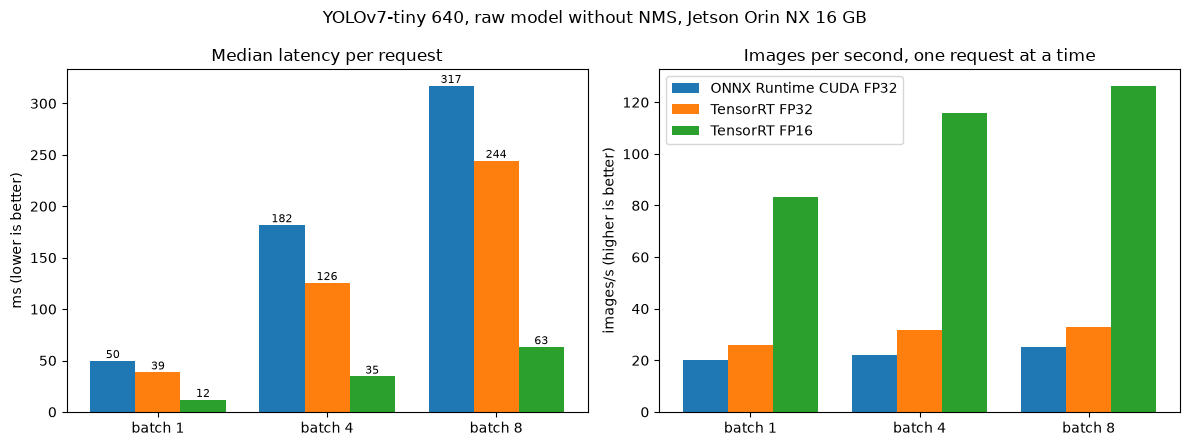

In [3]:
fig, (latency, throughput) = plt.subplots(1, 2, figsize=(12, 4.5))
width = 0.8 / len(variants)
for i, v in enumerate(variants):
    x = [j + (i - (len(variants) - 1) / 2) * width for j in range(len(batches))]
    bars = latency.bar(x, [value[v, b]["median_ms"] for b in batches], width, label=v)
    latency.bar_label(bars, fmt="%.0f", fontsize=8)
    throughput.bar(x, [value[v, b]["serial_images_per_second"] for b in batches], width, label=v)
for ax, title, unit in ((latency, "Median latency per request", "ms (lower is better)"),
                        (throughput, "Images per second, one request at a time", "images/s (higher is better)")):
    ax.set_xticks(range(len(batches)), [f"batch {b}" for b in batches])
    ax.set_title(title)
    ax.set_ylabel(unit)
throughput.legend()
fig.suptitle("YOLOv7-tiny 640, raw model without NMS, Jetson Orin NX 16 GB")
fig.tight_layout()

### Reading the results

- **TensorRT FP16 is 4–5× faster than ONNX Runtime CUDA FP32** on the same graph and timer;
  TensorRT FP32 alone gives 1.3–1.45×. Most of the gain comes from enabling FP16.
- The station was **busy** (GPU load rose from 55% to 90% during the run): absolute times are
  higher than on an idle device. Variants were interleaved in shuffled rounds to spread that
  contention, so treat the ratios as indicative, not as idle-device figures.
- FP16 outputs differ slightly from FP32 (some raw box coordinates by up to 14 px on random
  input): a numerical sanity check, **not** an accuracy evaluation.
- This is raw model latency. Pipeline throughput (decode + batch + track + analytics) is
  measured separately, with `eais-tools check perf`.

## 6. Packaging reproducibly

```mermaid
flowchart LR
    SRC["Repository<br/>+ built engine and parser"] --> B["eais-tools aip build<br/>--include-file .include"]
    B --> D["dist/"]
    D --> CK{"tools/check_package.py<br/>exact file set + SHA-256"}
    CK -- "OK" --> X["eais-tools aip export"]
    X --> A[["AIPV1EMI0001_dist.tgz"]]
    A --> CK2{"check_package.py --archive"}
    CK -- "unexpected / missing / changed" --> F["fail"]
```

- **Allowlist, not denylist**: `.include` names individual files. Directory entries would also
  ship `node_modules/`, caches or `flows_cred.json` (credentials).
- **Verify the result, not the intent**: the package must contain exactly the expected files,
  byte-identical to the sources; no ONNX, no symlinks, no path traversal.
- **Same check everywhere**: the build notebook on the station and the CI release workflow run
  the same script.
- **Weights outside Git**, versioned on Hugging Face and verified by SHA-256 at download.

## 7. Validating in layers

```mermaid
flowchart LR
    S["Static<br/>eais-tools aip check<br/>Triton / DeepStream validators"] --> E["Engine smoke test<br/>loads and runs on this device"]
    E --> P["Pipeline test<br/>eais-tools pipeline test<br/>decode, infer, track, callback"]
    P --> C["Output contract<br/>schema + detections > 0"]
    C --> U["Dashboard<br/>human check"]
```

- Static checks are fast but cannot run the tracker or the GPU.
- The **station-managed pipeline test** runs the real pipeline headless, on a sample video.
- **A started pipeline, or a timeout, is not a pass**: the test requires valid callback
  messages *with* detections.
- The callback output is a documented, versioned **contract** (`doc/USER_MANUAL.md`), checked
  automatically: applications depend on it, not on the model.

## 8. Operating in the field

- **Business logic as a Node-RED flow** shipped with the AIP (`logic/`): subscribes to the
  pipeline's callback, normalizes counts per class, ROI and line crossing.
- **Dashboard shipped with the AIP** (`dashboard/`, Vue 3 UIBuilder): live HLS video and counts;
  browser libraries are vendored so it works **offline**.
- **No secrets in packages**: `flows_cred.json` never ships; credentials are configured on the station.
- **One package, many stations**: install the verified `.tgz`; rebuild the engine from ONNX
  when the SDK generation changes.
- **Watch the device, not just the model**: memory headroom (shared CPU/GPU), GPU load and
  temperature, stream health.

## 9. Checklist: from model to field

- [ ] Export a portable model (ONNX) and keep it as the source of truth, with checksums
- [ ] Build the engine **on** the target SDK stack; tag prebuilt engines with that stack
- [ ] Choose precision and batch profile deliberately, and size builder memory for a shared device
- [ ] Benchmark with **one** timing boundary for every backend; report conditions and medians
- [ ] Package with an allowlist and verify the exact package contents
- [ ] Validate statically, then on the real pipeline, then the output contract
- [ ] Ship the application logic and dashboard with the model, without secrets
- [ ] Make the whole path reproducible by someone else: a notebook, a CI workflow

## Live demo (optional)

Run on a station from `/data/aip/AIPV1EMI0001` after `localdev.ipynb` sections 0–5.
Set `LIVE = True` to execute.

In [4]:
import subprocess

LIVE = False
ENGINE = "models/AIPV1EMI0001_Yolo_Detector/1/yolov7-fp16-1x8x8.engine"
if LIVE:
    subprocess.run(["python3", "tools/check_package.py", "--archive", "AIPV1EMI0001_dist.tgz"], check=True)
    log = subprocess.run(["/usr/src/tensorrt/bin/trtexec", f"--loadEngine={ENGINE}",
                          "--shapes=images:8x3x640x640", "--duration=10"],
                         capture_output=True, text=True, check=True).stdout
    print("\n".join(line for line in log.splitlines() if "Throughput" in line or "Latency:" in line))
    print("trtexec: GPU-side engine figures, a different boundary from section 5's table")

## Resources

- Source, build notebook and dashboard: [github.com/edge-ai/AIPV1EMI0001](https://github.com/edge-ai/AIPV1EMI0001)
- Weights (ONNX and prebuilt engine): [huggingface.co/Edgematrix-JP/AIPV1EMI0001](https://huggingface.co/Edgematrix-JP/AIPV1EMI0001)
- Benchmark harness and raw results: [`tools/benchmark.py`](tools/benchmark.py),
  [`doc/benchmarks/`](doc/benchmarks/)
- YOLOv7: [WongKinYiu/yolov7](https://github.com/WongKinYiu/yolov7)
- Talk: [luma.com/xkb4ai5f](https://luma.com/xkb4ai5f)